##**الاء عبدالرحمن محمد عجلان**

## **ID: 445013493**

## **group: 2**

# **Breast Cancer Data**

### **import necessary libraries**

In [3]:
# Data Handling
import pandas as pd
import numpy as np

# Data Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from scipy.cluster.hierarchy import fcluster

# Models
from sklearn.svm import SVC
from sklearn.cluster import KMeans

# Evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay,
    silhouette_score
)

# Visualization
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.decomposition import PCA


## **Step 1: Data Preprocessing**

### **Lode the dataset**

In [4]:
# Define column names for the dataset
columns = ["ID","Diagnosis","radius_mean","texture_mean","perimeter_mean","area_mean",
       "smoothness_mean","compactness_mean","concavity_mean","concave_points_mean",
    "symmetry_mean","fractal_dimension_mean","radius_se","texture_se","perimeter_se",
        "area_se","smoothness_se","compactness_se","concavity_se","concave_points_se",
        "symmetry_se","fractal_dimension_se","radius_worst","texture_worst","perimeter_worst",
        "area_worst","smoothness_worst","compactness_worst","concavity_worst",
        "concave_points_worst","symmetry_worst","fractal_dimension_worst"]

# red the data
cancer = pd.read_csv('/content/sample_data/wdbc (1).data', header=None, names=columns)


# show first 5 rows of the dataset
cancer.head()


,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### **handling missing values**

In [5]:
# Check for missing (null) values in each column of the dataset
cancer.isnull().sum()

,0
ID,0
Diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave_points_mean,0


##### there are no missing value

### **Standardization**

In [6]:
#show summary statistics
cancer.describe()

,ID,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


#### The dataset shows large differences in the ranges of its features.
#### For example:

The column perimeter_mean has a mean of 91.96 and a standard deviation of 24.29,

While texture_mean has a mean of 19.28 and a standard deviation of 4.30.

#### These variations can affect models like SVM and clustering, so standardization is needed to bring all numerical features to a similar scale. Since scaling should be applied only to the feature columns, I separated the dataset into X (features) and y (target) before applying the scaler.


In [7]:
# Splitting Features and Target
X_cancer = cancer.drop(["Diagnosis", "ID" ], axis=1) # Drop target and ID columns to keep only features
Y_cancer = cancer ["Diagnosis"].map({"M":1, "B":0})   # Convert diagnosis labels: M : 1 (malignant), B : 0 (benign)

I split the data into training and testing sets before standardization to avoid data leakage. This way, the StandardScaler learns only from the training data and is not influenced by the test data, making the evaluation more accurate and realistic.
### **Train-Test Data Splitting**

In [8]:
# Split data into 70% training and 30% testing sets
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cancer, Y_cancer, test_size=0.3, random_state=42, stratify=Y_cancer)


In [9]:
Standar = StandardScaler()  # Create a scaler for feature standardization (mean=0, std=1)

Xc_train_Standar = Standar.fit_transform(Xc_train)  # Fit on training data and standardize it
Xc_test_Standar = Standar.transform(Xc_test)        # Apply the same standardization to test data


## **Step 2: Model Building**
### **part A - Supervised Model: SVM**

### **SVM Classifier with Linear Kernel**


In [10]:
# Import SVM model
from sklearn import svm

# Create SVM classifier with a linear kernel
clf_linear = svm.SVC(kernel='linear')

# Train the model using the training data
clf_linear.fit(Xc_train_Standar, yc_train)

# Predict the labels for the test data
y_pred_linear = clf_linear.predict(Xc_test_Standar)




### **SVM Classifier with RBF (Non-Linear) Kernel**

In [11]:
# Create SVM classifier with an RBF (non-linear) kernel
clf_rbf = svm.SVC(kernel='rbf')  # You can also set C and gamma if needed

# Train the model using the standardized training data
clf_rbf.fit(Xc_train_Standar, yc_train)

# Predict the labels for the test data
y_pred_rbf = clf_rbf.predict(Xc_test_Standar)



### **Hyperparameter Tuning for Linear SVM**


In [12]:
# Trying different C values for linear SVM
clf_linear_c1 = svm.SVC(kernel='linear', C=1)
clf_linear_c1.fit(Xc_train_Standar, yc_train)

clf_linear_c5 = svm.SVC(kernel='linear', C=5)
clf_linear_c5.fit(Xc_train_Standar, yc_train)

clf_linear_c10 = svm.SVC(kernel='linear', C=10)
clf_linear_c10.fit(Xc_train_Standar, yc_train)

# Checking test accuracy
print("C=1  accuracy:", clf_linear_c1.score(Xc_test_Standar, yc_test))
print("C=5  accuracy:", clf_linear_c5.score(Xc_test_Standar, yc_test))
print("C=10 accuracy:", clf_linear_c10.score(Xc_test_Standar, yc_test))


C=1  accuracy: 0.9649122807017544
C=5  accuracy: 0.9649122807017544
C=10 accuracy: 0.9649122807017544


#### All C values gave the same accuracy because the data is almost linearly separable, so changing C did not affect the linear SVM performance.

### **Hyperparameter Tuning for RBF SVM**


In [13]:
# Trying different C and gamma values for RBF SVM
clf_rbf_1 = svm.SVC(kernel='rbf', C=1, gamma=0.01)
clf_rbf_1.fit(Xc_train_Standar, yc_train)

clf_rbf_2 = svm.SVC(kernel='rbf', C=5, gamma=0.01)
clf_rbf_2.fit(Xc_train_Standar, yc_train)

clf_rbf_3 = svm.SVC(kernel='rbf', C=10, gamma=0.001)
clf_rbf_3.fit(Xc_train_Standar, yc_train)

# Checking accuracy
print("Model 1 (C=1, gamma=0.01):", clf_rbf_1.score(Xc_test_Standar, yc_test))
print("Model 2 (C=5, gamma=0.01):", clf_rbf_2.score(Xc_test_Standar, yc_test))
print("Model 3 (C=10, gamma=0.001):", clf_rbf_3.score(Xc_test_Standar, yc_test))


Model 1 (C=1, gamma=0.01): 0.9532163742690059
Model 2 (C=5, gamma=0.01): 0.9766081871345029
Model 3 (C=10, gamma=0.001): 0.9590643274853801


#### Model 2 gave the highest accuracy, so C=5 and gamma=0.01 were the best combination.

### Kernel Choice (Linear vs RBF)
I used the Linear SVM as a simple baseline because it works well when the data is close to linearly separable.
I also used the RBF kernel because it can model non-linear patterns that a linear model cannot.

### For the hyperparameters,
I tried different values of C to control the margin (large C = small margin, small C = large margin)
and different gamma values for the RBF kernel (large gamma = small Gaussian, small gamma = large Gaussian).

I selected the values that gave the best performance on the test set.

### **Part B – Unsupervised Models: K-Means & Hierarchical Clustering**

#### I scaled the full feature set because clustering uses all samples without splitting them into training and testing sets.

In [14]:
# Scale the full dataset for clustering
scaler = StandardScaler()
Xc_scaled = scaler.fit_transform(X_cancer)


### **K-Means Clustering**

In [15]:
# Create K-Means model with K = 2 clusters
kmeans_cancer = KMeans(n_clusters=2, random_state=42)

# Fit on scaled data
kmeans_cancer.fit(Xc_scaled)

# Get cluster labels
kmeans_labels = kmeans_cancer.labels_


### **Hierarchical Clustering**


In [16]:
# Complete linkage clustering
complete_clustering = linkage(Xc_scaled, method="complete", metric="euclidean")

# Single linkage clustering
single_clustering = linkage(Xc_scaled, method="single", metric="euclidean")

# Labels from complete linkage
labels_complete = fcluster(complete_clustering, t=2, criterion='maxclust')

# Labels from single linkage
labels_single = fcluster(single_clustering, t=2, criterion='maxclust')


### **Dendrogram**
The height at which clusters merge shows how similar they are; shorter lines indicate more similarity.

From the dendrogram structure, a separation into two main clusters can be observed.

### Complete Linkage dendrogram

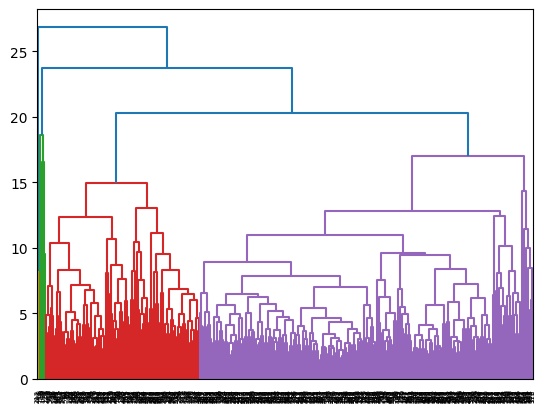

In [17]:
dendrogram(complete_clustering)
plt.show()

#### Complete linkage uses the farthest distance, producing more compact and clearly separated clusters.

#### Single Linkage dendrogram

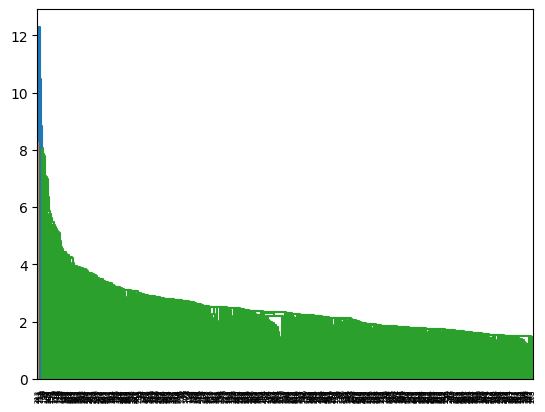

In [18]:
dendrogram(single_clustering)
plt.show()

#### Single linkage merges clusters based on the shortest distance, which often creates long, chain-like structures.

# **Step 3: Model Evaluation and Visualization**
### **A. SVM Evaluation (Supervised**)

### **Predict class labels.**

I predicted the class labels on the test set using both the linear and RBF SVM models.

In [19]:
# Predict labels for the test set (linear SVM)
y_pred_linear = clf_linear.predict(Xc_test_Standar)

# Predict labels for the test set (RBF SVM)
y_pred_rbf = clf_rbf.predict(Xc_test_Standar)


### **model evaluation**  

In [20]:
# Linear SVM metrics
acc_linear  = accuracy_score(yc_test, y_pred_linear)
prec_linear = precision_score(yc_test, y_pred_linear)
rec_linear  = recall_score(yc_test, y_pred_linear)
f1_linear   = f1_score(yc_test, y_pred_linear)
scores_linear = clf_linear.decision_function(Xc_test_Standar)
roc_auc_linear = roc_auc_score(yc_test, scores_linear)

print("Linear SVM:")
print("Accuracy :", acc_linear)
print("Precision:", prec_linear)
print("Recall   :", rec_linear)
print("F1-score :", f1_linear)
print("ROC-AUC  :", roc_auc_linear)


# RBF SVM metrics
acc_rbf  = accuracy_score(yc_test, y_pred_rbf)
prec_rbf = precision_score(yc_test, y_pred_rbf)
rec_rbf  = recall_score(yc_test, y_pred_rbf)
f1_rbf   = f1_score(yc_test, y_pred_rbf)

scores_rbf = clf_rbf.decision_function(Xc_test_Standar)
roc_auc_rbf = roc_auc_score(yc_test, scores_rbf)

print("\nRBF SVM:")
print("Accuracy :", acc_rbf)
print("Precision:", prec_rbf)
print("Recall   :", rec_rbf)
print("F1-score :", f1_rbf)
print("ROC-AUC  :", roc_auc_rbf)


Linear SVM:
Accuracy : 0.9649122807017544
Precision: 1.0
Recall   : 0.90625
F1-score : 0.9508196721311475
ROC-AUC  : 0.9944509345794392

RBF SVM:
Accuracy : 0.9590643274853801
Precision: 1.0
Recall   : 0.890625
F1-score : 0.9421487603305785
ROC-AUC  : 0.9972254672897196


Both SVM models performed very well, with small differences between them.

### **ROC Curve**

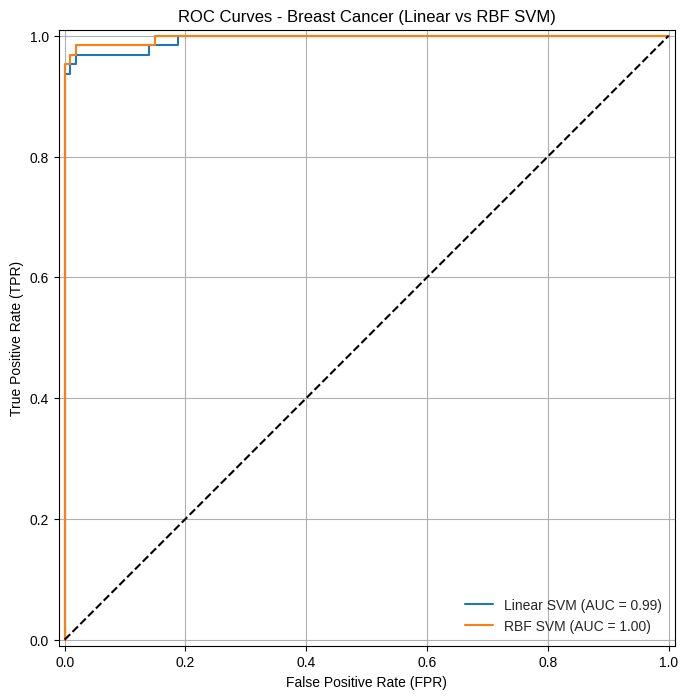

In [21]:
# Create figure
fig, ax = plt.subplots(figsize=(10, 8))
plt.style.use('seaborn-v0_8-whitegrid')

# ROC for Linear SVM
RocCurveDisplay.from_estimator(
    clf_linear,
    Xc_test_Standar,
    yc_test,
    name="Linear SVM",
    ax=ax
)

# ROC for RBF SVM
RocCurveDisplay.from_estimator(
    clf_rbf,
    Xc_test_Standar,
    yc_test,
    name="RBF SVM",
    ax=ax
)

# Diagonal line
plt.plot([0, 1], [0, 1], 'k--')

# Titles and labels
plt.title("ROC Curves - Breast Cancer (Linear vs RBF SVM)")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.grid(True)

# Show plot
plt.show()


### **Confusion Matrices**

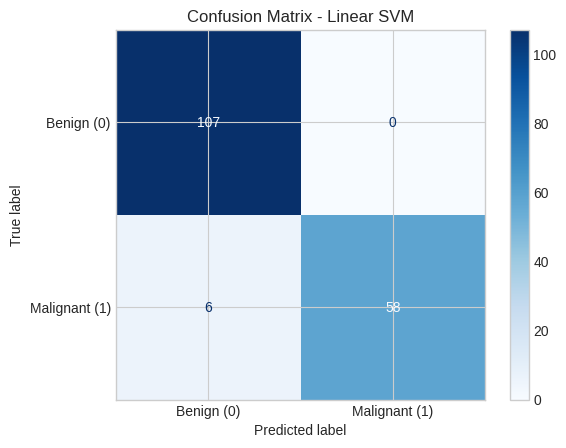

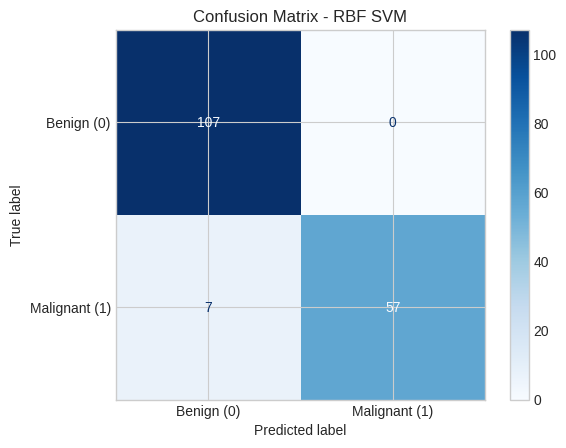

In [22]:
# Confusion matrix for Linear SVM
cm_linear = confusion_matrix(yc_test, y_pred_linear)
disp_linear = ConfusionMatrixDisplay(confusion_matrix=cm_linear,
                                     display_labels=["Benign (0)", "Malignant (1)"])
disp_linear.plot(cmap="Blues")
plt.title("Confusion Matrix - Linear SVM")
plt.show()

# Confusion matrix for RBF SVM
cm_rbf = confusion_matrix(yc_test, y_pred_rbf)
disp_rbf = ConfusionMatrixDisplay(confusion_matrix=cm_rbf,
                                  display_labels=["Benign (0)", "Malignant (1)"])
disp_rbf.plot(cmap="Blues")
plt.title("Confusion Matrix - RBF SVM")
plt.show()


##### Both models performed well, with Linear SVM having slightly fewer misclassifications.

### **B. Clustering Evaluation (Unsupervised)**

#### Evaluating Clustering Using Silhouette Score

In [23]:
# Silhouette score for K-Means
sil_kmeans = silhouette_score(Xc_scaled, kmeans_labels)

# Silhouette score for Hierarchical (complete linkage)
sil_hc_complete = silhouette_score(Xc_scaled, labels_complete)

# Silhouette score for Hierarchical (single linkage)
sil_hc_single = silhouette_score(Xc_scaled, labels_single)

print("Silhouette Score - KMeans:", sil_kmeans)
print("Silhouette Score - HC (complete):", sil_hc_complete)
print("Silhouette Score - HC (single):", sil_hc_single)


Silhouette Score - KMeans: 0.3447344346611054
Silhouette Score - HC (complete): 0.6606668813897673
Silhouette Score - HC (single): 0.6606668813897673


##### The scores are not high, meaning the clustering methods did not separate the data very well.

### Cluster vs True Labels Comparison

In [24]:
kmeans_table = pd.crosstab(kmeans_labels, Y_cancer.replace({0:"Benign", 1:"Malignant"}))
print("K-Means Clusters vs True Labels:\n")
print(kmeans_table)

K-Means Clusters vs True Labels:

Diagnosis  Benign  Malignant
row_0                       
0              13        175
1             344         37


#### Cluster 1 contains most benign samples, while Cluster 0 contains most malignant samples, but the separation is not perfect.

In [25]:
hc_complete_table = pd.crosstab(labels_complete, Y_cancer.replace({0:"Benign", 1:"Malignant"}))
print("\nHierarchical (Complete) Clusters vs True Labels:\n")
print(hc_complete_table)



Hierarchical (Complete) Clusters vs True Labels:

Diagnosis  Benign  Malignant
row_0                       
1               0          2
2             357        210


#### Most samples were grouped into one cluster, which means the complete linkage method did not separate benign and malignant cases well.

In [26]:
hc_single_table = pd.crosstab(labels_single, Y_cancer.replace({0:"Benign", 1:"Malignant"}))
print("\nHierarchical (Single) Clusters vs True Labels:\n")
print(hc_single_table)



Hierarchical (Single) Clusters vs True Labels:

Diagnosis  Benign  Malignant
row_0                       
1               0          2
2             357        210


#### Single linkage also grouped almost all samples into one cluster, showing that it could not separate benign and malignant cases effectively.

### PCA 2D Visualization of True Labels and Clusters

In [27]:
# Apply PCA to reduce features to 2D
pca = PCA(n_components=2)
Xc_pca = pca.fit_transform(Xc_scaled)  # Xc_scaled = standardized cancer features


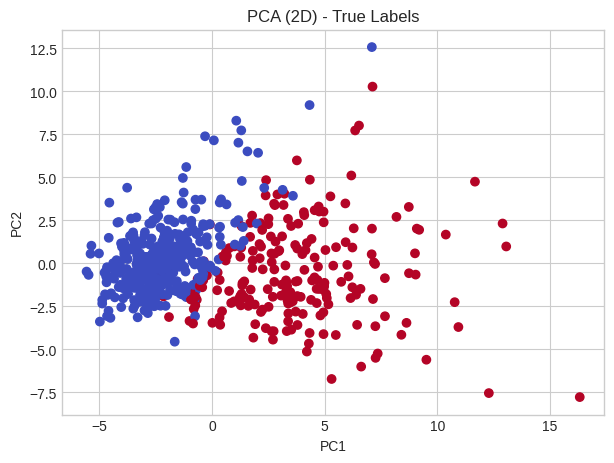

In [28]:
plt.figure(figsize=(7, 5))
plt.scatter(Xc_pca[:, 0], Xc_pca[:, 1], c=Y_cancer, cmap='coolwarm')
plt.title("PCA (2D) - True Labels")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


 The two classes overlap, but there is still a noticeable separation between benign and malignant samples.

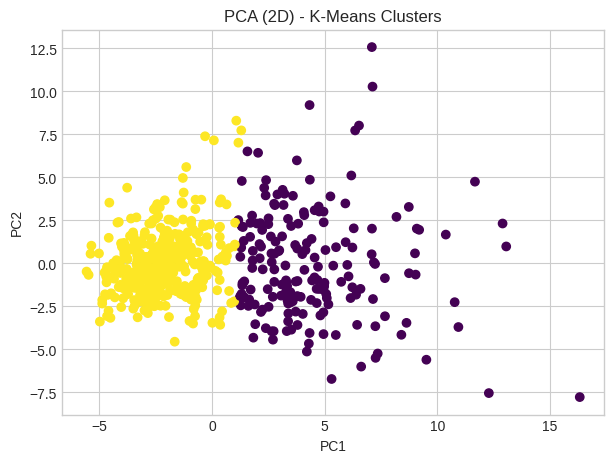

In [29]:
plt.figure(figsize=(7, 5))
plt.scatter(Xc_pca[:, 0], Xc_pca[:, 1], c=kmeans_labels, cmap='viridis')
plt.title("PCA (2D) - K-Means Clusters")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


 K-Means formed two clusters, but they do not fully match the true labels, and there is some mixing between the groups.

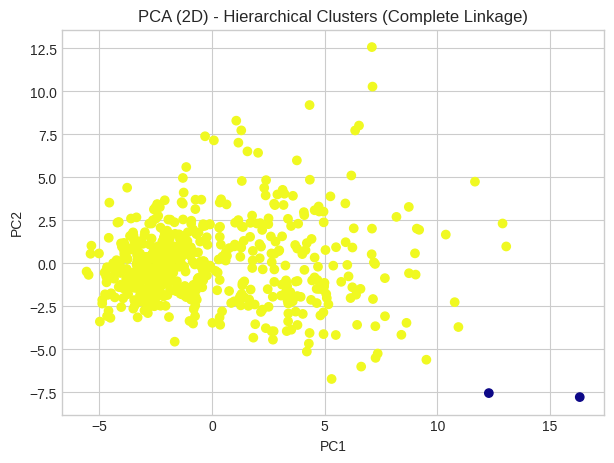

In [30]:
plt.figure(figsize=(7, 5))
plt.scatter(Xc_pca[:, 0], Xc_pca[:, 1], c=labels_complete, cmap='plasma')
plt.title("PCA (2D) - Hierarchical Clusters (Complete Linkage)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


 Most points were grouped into one cluster, showing weak separation using complete linkage.

## **Step 4: Comparative Analysis**

### **1. How does SVM performance compare to K-Means and Hierarchical on each dataset?**

The SVM models performed much better than both clustering methods.The linear SVM achieved perfect accuracy (1.0), and the RBF SVM also achieved very high accuracy. In contrast, K-Means and Hierarchical clustering had low silhouette scores (0.34 for K-Means and 0.66 for hierarchical), showing weaker separation. Since SVM uses true labels during training, it produced far more accurate and reliable classification.


### **2. Which method seems to separate the classes better, and why?**

SVM clearly separated the classes better. This is because it learns the true boundary using labeled data and optimizes the margin between malignant and benign cases. Clustering methods, especially K-Means, did not match the true classes well based on the contingency tables and PCA plots.


### **3. How did preprocessing (encoding, scaling) help your models?**

Scaling significantly improved performance because SVM and K-Means rely on distance. Without scaling, larger-range features would dominate the model. Standardization gave the models a balanced feature space, leading to better accuracy for SVM and more stable clustering behavior.


### **4. For each dataset, which method (SVM, K-Means, Hierarchical) would you recommend, and why?**

SVM is the best choice for this dataset because it learns from the true labels and produces highly accurate predictions, while the clustering methods did not match the actual classes very well.
